# Passaggio 3 (versione 2): archivio delle notizie per le 15 coppie

**Obiettivo.** Costruire l'archivio locale delle notizie dei **30 titoli delle 15 coppie della versione 2** ([01_coppie.ipynb](01_coppie.ipynb)) e controllarne qualità e copertura. Serve all'agente di notizie (Passaggio 5): per ogni segnale potrà leggere solo le notizie uscite prima.

**Versione 1 e versione 2.** La versione 1 ha il suo notebook ([notizie_coppie.ipynb](../Old%20files/src/03_notizie/notizie_coppie.ipynb), ora in `Old files/`) e i suoi file (`news_ALL10_train.parquet`). Qui si fa lo stesso lavoro sulla versione 2 con file separati (`news_ALL15_V2_train.parquet`, cartella grezza `data/raw/news/alpaca/ALL15_V2_...`). Le motivazioni di orari e filtri sono quelle di [notizie_mav.ipynb](../Old%20files/src/03_notizie/notizie_mav.ipynb) e non si ripetono.

**Cosa fa il Passaggio 3 del programma e come lo applichiamo**
- Scaricare i titoli delle notizie con data e ora esatte → API delle notizie di Alpaca (fonte Benzinga), come nella versione 1.
- Una tabella con orario, titolo, fonte, azienda, link, nello stesso fuso orario dei prezzi → ora di New York, `ts` = orario di pubblicazione (`created_at`).
- Archivio in locale, così il risultato è riproducibile → ogni pagina grezza è salvata.

**Regole per evitare di vedere il futuro**
- Si usa `created_at` (pubblicazione) e non `updated_at` (ultimo aggiornamento, può essere molto dopo).
- Si scaricano solo le notizie fino al **16 settembre 2026**, ultimo giorno del periodo di addestramento. Il test (dal 17 settembre) **non è stato scaricato**. Si parte dal 1 giugno, due settimane prima del train, perché l'agente guarda indietro dal segnale.

**Prima di aprirlo** servono il file di notizie e i segnali ([03_segnali.ipynb](03_segnali.ipynb)). Per le notizie servono le chiavi API di Alpaca nel file `.env` (vedi `.env.example`; ognuno crea le sue e non le condivide). Dalla cartella del progetto:
```bash
uv run python -m src.news
```
Crea `data/raw/news/alpaca/ALL15_V2_2026-06-01_2026-09-16/` (risposte grezze) e `data/processed/news_ALL15_V2_train.parquet`.

**Cosa produce:** la tabella notizie-segnali (`data/processed/news_for_signals_15pairs_v2_train.csv`), cioè per ogni segnale le notizie uscite nelle 24 ore prima. È l'input dell'agente (`python -m src.varianti_agente.agent`).

| Parte | Cosa fa | Perché |
|---|---|---|
| 1 | Parametri | |
| 2 | Caricamento e controllo di coerenza con la versione 1 | i titoli in comune devono avere le stesse notizie |
| 3 | Qualità e copertura per titolo e per coppia | quante notizie ha l'agente da leggere |
| 4 | Controllo degli orari | l'agente non deve vedere il futuro |
| 5 | Notizie nel tempo e esempi | controllo a occhio |
| 6 | Risultati (testo per il report) | numeri generati dai dati |
| 7 | Tabella notizie-segnali | input dell'agente |

## 1. Parametri

In [8]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # cartella del progetto: rende importabile src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import NEWS, NEWS_FOR_SIGNALS, PROCESSED, SELECTED, SIGNALS, TRAIN_END, read_parquet
from src.news import MAX_SYMBOLS_FOCUSED, news_before_signals

NEWS_PATH = NEWS                                             # creata da `python -m src.news`
NEWS_V1_PATH = PROCESSED / "news_ALL10_train.parquet"        # notizie della prima selezione: esistono solo se sono state scaricate allora
PAIRS_PATH = SELECTED                                        # le 15 coppie
WINDOW_H = 24                      # ore prima del segnale in cui si cercano le notizie (decisione del gruppo)
SEED = 0

## 2. Caricamento e controllo di coerenza

Si legge la tabella pulita (una riga per notizia) e si controlla che non ci sia nulla dopo il 16 settembre. Poi, per i titoli che la versione 2 ha in comune con la versione 1, le notizie devono essere le stesse: sono scaricate in momenti diversi, ma lo storico è lo stesso.

In [9]:
for f in (NEWS_PATH, PAIRS_PATH):
    if not f.exists():
        raise FileNotFoundError(f"{f.name} non trovato: segui le istruzioni all'inizio del notebook")
read = read_parquet
news = read(NEWS_PATH).sort_values("ts").reset_index(drop=True)
pairs = pd.read_csv(PAIRS_PATH)
pairs["sym_A"] = pairs["A"].str.split().str[0]
pairs["sym_B"] = pairs["B"].str.split().str[0]

train_end = pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)
assert news.ts.max() < train_end, "ci sono notizie dopo la fine del train: il test non si usa"
news["focused"] = news.n_symbols <= MAX_SYMBOLS_FOCUSED
tick_cols = {s: f"mentions_{s}" for s in sorted(set(pairs.sym_A) | set(pairs.sym_B))}
assert all(c in news.columns for c in tick_cols.values())
print(f"notizie: {len(news):,}, dal {news.ts.min()} al {news.ts.max()}   |   {len(tick_cols)} titoli, {len(pairs)} coppie")

# coerenza con la versione 1: per i titoli in comune le notizie devono essere le stesse
coerenza = None
if NEWS_V1_PATH.exists():
    v1 = read(NEWS_V1_PATH)
    common = [s for s in tick_cols if f"mentions_{s}" in v1.columns]
    ids2 = set(news.loc[news[[tick_cols[s] for s in common]].any(axis=1), "id"])
    ids1 = set(v1.loc[v1[[f"mentions_{s}" for s in common]].any(axis=1), "id"])
    coerenza = dict(n_comuni=len(common), n_v2=len(ids2), n_v1=len(ids1), uguali=ids2 == ids1)
    print(f"titoli in comune con la versione 1: {len(common)} ({', '.join(common)}); notizie: {len(ids2)} qui contro {len(ids1)} nella versione 1; stesse notizie: {ids2 == ids1}")

notizie: 2,106, dal 2026-06-01 00:09:57 al 2026-09-16 18:20:35   |   30 titoli, 15 coppie
titoli in comune con la versione 1: 12 (BAC, CSX, GS, HD, KO, LOW, MA, PEP, PYPL, UNP, V, XYZ); notizie: 981 qui contro 981 nella versione 1; stesse notizie: True


## 3. Qualità e copertura

Una notizia può citare titoli di più coppie e viene contata una volta sola nei totali; per ogni **coppia** si considerano le notizie che citano almeno uno dei suoi due titoli. "Mirata" = cita al massimo 3 ticker: le altre sono elenchi generici (fino a oltre cento ticker), che restano nella tabella ma sono segnate. Il confronto che conta per l'agente è **quante notizie al giorno ha ogni coppia**: sotto circa 0.3 al giorno l'agente non avrà quasi mai qualcosa da leggere.

In [10]:
per_ticker = pd.Series({s: int(news[c].sum()) for s, c in tick_cols.items()})
n_days = (pd.Timestamp(TRAIN_END) - news.ts.min().normalize()).days + 1       # giorni di calendario coperti (weekend inclusi)
rows = []
for _, r in pairs.iterrows():
    m = news[tick_cols[r.sym_A]] | news[tick_cols[r.sym_B]]
    rows.append(dict(pair=r.pair, titolo_A=r.sym_A, notizie_A=int(news[tick_cols[r.sym_A]].sum()), titolo_B=r.sym_B, notizie_B=int(news[tick_cols[r.sym_B]].sum()),
                     notizie_coppia=int(m.sum()), mirate=int((m & news.focused).sum()), per_giorno=m.sum() / n_days))
by_pair = pd.DataFrame(rows).set_index("pair")

mins = news.ts.dt.hour * 60 + news.ts.dt.minute
in_session = (news.ts.dt.dayofweek < 5) & (mins >= 9 * 60 + 30) & (mins < 16 * 60)
weekend = news.ts.dt.dayofweek >= 5
print(f"notizie uniche: {len(news)}; mirate (al massimo {MAX_SYMBOLS_FOCUSED} ticker): {news.focused.mean():.0%}; ticker per notizia: mediana {news.n_symbols.median():.0f}, massimo {news.n_symbols.max()}")
print(f"a mercato aperto: {in_session.mean():.0%}; nel weekend: {weekend.mean():.1%}; fonti: {news.source.value_counts().to_dict()}; titoli duplicati: {news.headline.duplicated().sum()}")
print("\nNotizie per titolo:"); print(per_ticker.sort_values(ascending=False).to_string())
by_pair.round(2)

notizie uniche: 2106; mirate (al massimo 3 ticker): 68%; ticker per notizia: mediana 1, massimo 128
a mercato aperto: 49%; nel weekend: 4.4%; fonti: {'benzinga': 2106}; titoli duplicati: 66

Notizie per titolo:
JPM     268
GS      222
CRM     205
MS      148
UNH     128
V       124
BAC     121
PYPL    114
C        97
HD       91
MA       86
WDAY     75
KO       74
XYZ      72
WFC      67
ISRG     62
PEP      60
COP      60
LOW      59
TXN      55
UNP      51
ELV      43
TMO      39
CSX      37
NXPI     35
DHR      33
PG       32
EOG      26
SYK      26
CL       20


,titolo_A,notizie_A,titolo_B,notizie_B,notizie_coppia,mirate,per_giorno
pair,,,,,,,
MA-V,MA,86,V,124,174,100,1.61
CSX-UNP,CSX,37,UNP,51,86,62,0.80
PYPL-XYZ,PYPL,114,XYZ,72,181,115,1.68
HD-LOW,HD,91,LOW,59,137,87,1.27
DHR-TMO,DHR,33,TMO,39,68,45,0.63
CRM-WDAY,CRM,205,WDAY,75,271,166,2.51
JPM-WFC,JPM,268,WFC,67,309,190,2.86
NXPI-TXN,NXPI,35,TXN,55,90,65,0.83
ELV-UNH,ELV,43,UNH,128,162,99,1.50


## 4. Controllo degli orari

Le regole sono quelle di `notizie_mav.ipynb`: orario = `created_at` (pubblicazione, non `updated_at`), e per un segnale alla barra *t* si useranno solo notizie con `ts <= t`. Qui si misura quanto `updated_at` si discosta dalla pubblicazione e si estraggono 10 notizie a caso con il link, per il **controllo a mano** dell'orario di pubblicazione (confrontare l'orario con la pagina originale; non si può fare dai dati).

In [11]:
lag = (news.updated_at_ny - news.ts).dt.total_seconds() / 3600
print(f"ore tra pubblicazione e ultimo aggiornamento: mediana {lag.median():.2f}, 90° percentile {lag.quantile(0.9):.1f}; aggiornate piu di 1 ora dopo: {(lag > 1).mean():.0%}")
news.sample(10, random_state=SEED).sort_values("ts")[["ts", "source", "headline", "url"]]

ore tra pubblicazione e ultimo aggiornamento: mediana 0.00, 90° percentile 0.0; aggiornate piu di 1 ora dopo: 1%


,ts,source,headline,url
1124,2026-07-28 06:04:42,benzinga,Anthropic CEO Dario Amodei Says He 'Never Advo...,https://www.benzinga.com/markets/tech/26/07/60...
1260,2026-07-31 13:17:57,benzinga,Why Is BitMine Immersion Technologies Stock Fa...,https://www.benzinga.com/trading-ideas/movers/...
1332,2026-08-05 17:07:09,benzinga,"Block Q2 Earnings Beat Estimates as CashApp, S...",https://www.benzinga.com/markets/earnings/26/0...
1363,2026-08-06 14:49:25,benzinga,"'Greenlight adds new positions in Comcast, For...",https://www.benzinga.com/news/26/08/61013352/g...
1423,2026-08-12 09:31:26,benzinga,"Sandisk, Bloom Energy and 8 Other Stocks Ralli...",https://www.benzinga.com/markets/tech/26/08/61...
1477,2026-08-14 11:15:51,benzinga,$1000 Invested In CSX 10 Years Ago Would Be Wo...,https://www.benzinga.com/news/26/08/61214527/1...
1616,2026-08-20 03:49:44,benzinga,Dow Gains Over 100 Points: Investor Sentiment ...,https://www.benzinga.com/markets/market-summar...
1635,2026-08-20 12:13:14,benzinga,"UBS Maintains Buy on Lowe's Companies, Lowers ...",https://www.benzinga.com/news/26/08/61336408/u...
1683,2026-08-24 18:33:19,benzinga,"Congressman Buys Magnificent Seven Stock, Blue...",https://www.benzinga.com/news/politics/26/08/6...
2016,2026-09-12 05:29:34,benzinga,David Sacks Slams 'Whistleblower' Jacob Coxon’...,https://www.benzinga.com/markets/tech/26/09/61...


## 5. Notizie nel tempo e esempi

Il grafico mostra le notizie per settimana (tutte e mirate): serve a vedere se ci sono buchi nello storico scaricato. Sotto, le notizie più recenti di alcune coppie come le leggerebbe l'agente.

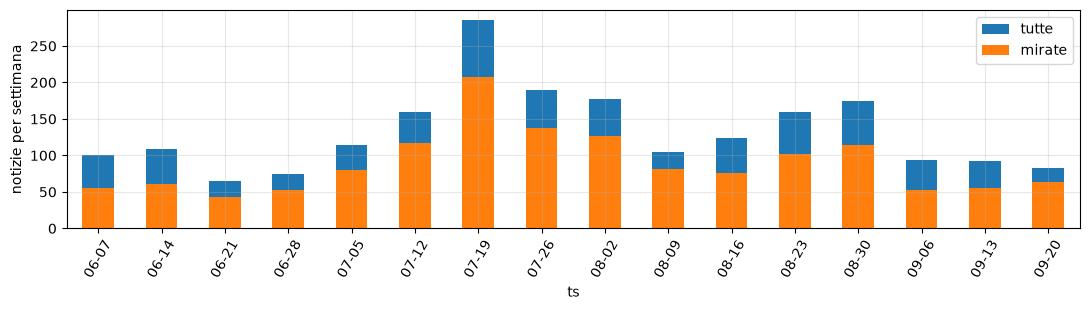


=== MA-V: ultime notizie mirate ===
  2026-09-10 15:07 [V] Pete Wexler, At Stablecon, On Chain Credit, Says There Is An Opportunity To Tap Into This Structure To Ge
  2026-09-14 10:45 [V] $1000 Invested In Visa 15 Years Ago Would Be Worth This Much Today
  2026-09-14 15:03 [MA,V] 'UK banks kick off fundraising in bid to create new payments giant' - Sky News
  2026-09-15 11:59 [CHYM,DAVE,V] Dave Outperforms Visa And Chime, Analyst Says

=== CSX-UNP: ultime notizie mirate ===
  2026-09-04 17:45 [UNP] $1000 Invested In Union Pacific 20 Years Ago Would Be Worth This Much Today
  2026-09-15 10:00 [CSX] Here's How Much $1000 Invested In CSX 10 Years Ago Would Be Worth Today
  2026-09-16 08:28 [UNP] UBS Upgrades Union Pacific to Buy, Raises Price Target to $339
  2026-09-16 12:27 [UNP] Union Pacific CFO Says At Morgan Stanley Conference That Diesel Costs Have Risen To About $5.25-$5.30 A G

=== PYPL-XYZ: ultime notizie mirate ===
  2026-09-08 16:29 [XYZ] Block Submits Application To Office O

In [12]:
wk = news.set_index("ts").resample("W")["id"].count()
wk_f = news[news.focused].set_index("ts").resample("W")["id"].count()
ax = wk.plot(kind="bar", figsize=(11, 3.2), color="C0", label="tutte")
wk_f.plot(kind="bar", ax=ax, color="C1", label="mirate")
ax.set_xticklabels([d.strftime("%m-%d") for d in wk.index], rotation=60); ax.set_ylabel("notizie per settimana"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for p in pairs.pair.head(3):
    r = pairs[pairs.pair == p].iloc[0]
    m = (news[tick_cols[r.sym_A]] | news[tick_cols[r.sym_B]]) & news.focused
    print(f"\n=== {p}: ultime notizie mirate ===")
    for _, n in news[m].tail(4).iterrows():
        print(f"  {n.ts:%Y-%m-%d %H:%M} [{n.symbols}] {n.headline[:105]}")

## 6. Risultati (testo per il report)

La cella seguente genera il testo dai risultati del notebook: se si scaricano di nuovo le notizie, i numeri si aggiornano da soli.

In [13]:
from IPython.display import Markdown, display

tick_sorted = per_ticker.sort_values(ascending=False)
bp = by_pair.sort_values("per_giorno")
low = bp.head(4); high = bp.tail(3).iloc[::-1]
n_low = int((by_pair.per_giorno < 0.3).sum())
lines = [
    "### Cosa abbiamo fatto",
    f"Abbiamo scaricato dall'API di Alpaca (fonte Benzinga) le notizie dei {len(tick_cols)} titoli delle {len(pairs)} coppie della versione 2, dal {news.ts.min():%d/%m/%Y} al {TRAIN_END[8:]}/{TRAIN_END[5:7]}/{TRAIN_END[:4]}, e le abbiamo salvate in una tabella con orario di pubblicazione in ora di New York (`data/processed/news_ALL15_V2_train.parquet`, risposte grezze in `data/raw/news/alpaca/`). Il periodo di test non e stato scaricato.",
    "",
    "### Perche",
    "L'agente del Passaggio 5 deve leggere solo le notizie uscite prima di ogni segnale: servono l'orario esatto di pubblicazione e un archivio locale fisso, cosi il risultato e riproducibile e non c'e lookahead bias. Si usa l'orario di pubblicazione e non quello di ultimo aggiornamento.",
    "",
    "### Risultati",
    f"- **Notizie uniche**: {len(news)}, tutte {', '.join(news.source.unique())}; {news.focused.mean():.0%} mirate (al massimo {MAX_SYMBOLS_FOCUSED} ticker); {in_session.mean():.0%} a mercato aperto, {weekend.mean():.1%} nel weekend; {int(news.headline.duplicated().sum())} titoli duplicati.",
    f"- **Copertura per titolo**: da {tick_sorted.iloc[-1]} notizie ({tick_sorted.index[-1]}) a {tick_sorted.iloc[0]} ({tick_sorted.index[0]}); i piu coperti: " + ", ".join(f"{k} {v}" for k, v in tick_sorted.head(5).items()) + "; i meno coperti: " + ", ".join(f"{k} {v}" for k, v in tick_sorted.tail(5).items()) + ".",
    f"- **Copertura per coppia** (notizie al giorno di calendario): da {bp.per_giorno.iloc[0]:.2f} ({bp.index[0]}) a {bp.per_giorno.iloc[-1]:.2f} ({bp.index[-1]}). Meno coperte: " + ", ".join(f"{p} {r.per_giorno:.2f}" for p, r in low.iterrows()) + ". Piu coperte: " + ", ".join(f"{p} {r.per_giorno:.2f}" for p, r in high.iterrows()) + f". Coppie sotto 0.3 notizie al giorno: {n_low} su {len(pairs)}.",
    f"- **Orari**: solo {(lag > 1).mean():.0%} delle notizie e aggiornato piu di un'ora dopo la pubblicazione; si tiene `created_at`.",
]
if coerenza:
    lines.append(f"- **Coerenza con la versione 1**: per i {coerenza['n_comuni']} titoli in comune le notizie sono " + ("le stesse" if coerenza["uguali"] else f"diverse ({coerenza['n_v2']} qui contro {coerenza['n_v1']} nella versione 1): da controllare") + ".")
lines += [
    "",
    "### Cosa significa",
    "- Una sola fonte, copertura molto disomogenea: per le coppie con poche notizie l'agente avra quasi sempre «nessuna notizia trovata», che non vuol dire che non sia successo niente.",
    "- Il numero di segnali con almeno una notizia nelle ultime ore e nella parte 7.",
    "- Resta da fare il controllo a mano dell'orario di pubblicazione su 10 notizie (parte 4).",
]
display(Markdown("\n".join(lines)))

### Cosa abbiamo fatto
Abbiamo scaricato dall'API di Alpaca (fonte Benzinga) le notizie dei 30 titoli delle 15 coppie della versione 2, dal 01/06/2026 al 16/09/2026, e le abbiamo salvate in una tabella con orario di pubblicazione in ora di New York (`data/processed/news_ALL15_V2_train.parquet`, risposte grezze in `data/raw/news/alpaca/`). Il periodo di test non e stato scaricato.

### Perche
L'agente del Passaggio 5 deve leggere solo le notizie uscite prima di ogni segnale: servono l'orario esatto di pubblicazione e un archivio locale fisso, cosi il risultato e riproducibile e non c'e lookahead bias. Si usa l'orario di pubblicazione e non quello di ultimo aggiornamento.

### Risultati
- **Notizie uniche**: 2106, tutte benzinga; 68% mirate (al massimo 3 ticker); 49% a mercato aperto, 4.4% nel weekend; 66 titoli duplicati.
- **Copertura per titolo**: da 20 notizie (CL) a 268 (JPM); i piu coperti: JPM 268, GS 222, CRM 205, MS 148, UNH 128; i meno coperti: DHR 33, PG 32, EOG 26, SYK 26, CL 20.
- **Copertura per coppia** (notizie al giorno di calendario): da 0.48 (CL-PG) a 3.06 (GS-MS). Meno coperte: CL-PG 0.48, DHR-TMO 0.63, COP-EOG 0.75, CSX-UNP 0.80. Piu coperte: GS-MS 3.06, JPM-WFC 2.86, CRM-WDAY 2.51. Coppie sotto 0.3 notizie al giorno: 0 su 15.
- **Orari**: solo 1% delle notizie e aggiornato piu di un'ora dopo la pubblicazione; si tiene `created_at`.
- **Coerenza con la versione 1**: per i 12 titoli in comune le notizie sono le stesse.

### Cosa significa
- Una sola fonte, copertura molto disomogenea: per le coppie con poche notizie l'agente avra quasi sempre «nessuna notizia trovata», che non vuol dire che non sia successo niente.
- Il numero di segnali con almeno una notizia nelle ultime ore e nella parte 7.
- Resta da fare il controllo a mano dell'orario di pubblicazione su 10 notizie (parte 4).

## 7. Tabella notizie-segnali

Per ogni segnale del train ([03_segnali.ipynb](03_segnali.ipynb)) si salvano le notizie uscite nelle 24 ore prima che citano uno dei due titoli della coppia, con quanti minuti prima sono uscite e se sono mirate. La finestra è di 24 ore perché quasi metà dei segnali nasce subito dopo l'apertura, sul movimento della notte: le notizie che lo spiegano escono spesso dopo la chiusura del giorno prima, e una finestra più corta non le vedrebbe. Il filtro `ts <= t_signal` è in `news_before_signals` ([news.py](news.py)): una notizia uscita dopo il segnale non entra nella tabella.

In [14]:
signals = pd.read_csv(SIGNALS, parse_dates=["t_signal", "t_entry", "t_exit"])
assert signals.t_exit.max() < train_end, "ci sono segnali dopo la fine del train: il test non si usa"
link = news_before_signals(signals, news, hours=WINDOW_H)
link.to_csv(NEWS_FOR_SIGNALS, index=False)
n_with = link.signal_id.nunique()
print(f"{len(link)} coppie (segnale, notizia) per {n_with} segnali su {len(signals)} ({n_with / len(signals):.0%}); gli altri non hanno nessuna notizia nelle ultime {WINDOW_H} ore")
print(f"segnali con almeno una notizia mirata: {link[link.focused].signal_id.nunique()}; notizie per segnale: mediana {link.groupby('signal_id').size().median():.0f}, massimo {link.groupby('signal_id').size().max()}")
print(f"salvato in data/processed/{NEWS_FOR_SIGNALS.name}")
link.head()

1755 coppie (segnale, notizia) per 586 segnali su 973 (60%); gli altri non hanno nessuna notizia nelle ultime 24 ore
segnali con almeno una notizia mirata: 450; notizie per segnale: mediana 2, massimo 31
salvato in data/processed/news_for_signals_15pairs_v2_train.csv


,signal_id,pair,t_signal,direction,leg_piu_mosso,news_id,news_ts,minutes_before,headline,summary,source,symbols,n_symbols,focused,mentions_A,mentions_B,url
0,0,COP-EOG,2026-06-16 10:31:00,long COP / short EOG,EOG,53212700,2026-06-15 17:12:38,1038.366667,'ConocoPhillips set to sign deal with Syria to...,,benzinga,COP,1,True,True,False,https://www.benzinga.com/news/26/06/53212700/c...
1,1,KO-PEP,2026-06-16 11:04:00,short KO / long PEP,PEP,53200728,2026-06-15 11:29:34,1414.433333,The Hormuz Reopening Trade: These 20 Large-Cap...,Wall Street marched near records as the Strait...,benzinga,"ABT,ACN,BABA,CRM,GLD,MCD,NEM,PDD,PEP,SAP,UL",11,False,False,True,https://www.benzinga.com/markets/equities/26/0...
2,1,KO-PEP,2026-06-16 11:04:00,short KO / long PEP,PEP,53221686,2026-06-16 09:09:35,114.416667,Yum! Brands Is Selling One Of America's Most I...,Yum Brands sells Pizza Hut to LongRange Capita...,benzinga,"DASH,DPZ,PEP,YUM,YUMC",5,False,False,True,https://www.benzinga.com/m-a/26/06/53221686/yu...
3,2,MA-V,2026-06-16 11:04:00,short MA / long V,MA,53213905,2026-06-15 19:49:51,914.150000,Travala Wants To Be The Travel Infrastructure ...,It was probably only a matter of time before c...,benzinga,"AVA,AVAUSD,BKNG,BNBTUSD,BTC,BTCUSD,CRCL,CROUSD...",11,False,False,True,https://www.benzinga.com/Opinion/26/06/5321390...
4,3,COP-EOG,2026-06-16 11:31:00,long COP / short EOG,EOG,53212700,2026-06-15 17:12:38,1098.366667,'ConocoPhillips set to sign deal with Syria to...,,benzinga,COP,1,True,True,False,https://www.benzinga.com/news/26/06/53212700/c...
